In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score, precision_score, f1_score,roc_auc_score
from sklearn.linear_model import LassoCV

plt.rcParams['figure.figsize']= (16,8)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

import warnings
warnings.filterwarnings("ignore")

Loading dataset
Index - Simply the Index

Product - Title of the product (as they're listed)

Category - Category into which product has been classified

Sub_category - Subcategory into which product has been kept

Brand - Brand of the product

Sale Price - Price at which product is sold

Market Price - Price of product in the market

Type - Type into which product falls

Rating - Rating the product has got from its consumers

Description - Description of the dataset (in detail)

In [52]:
df = pd.read_csv('/BigBasket Products.csv')

In [53]:
df.head()

,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


In [54]:
df.shape

(27555, 10)

In [55]:
df.columns

Index(['index', 'product', 'category', 'sub_category', 'brand', 'sale_price',
       'market_price', 'type', 'rating', 'description'],
      dtype='object')

In [56]:
# setting the index column as index of the dataset
df.set_index('index',inplace=True)
df.head()

,product,category,sub_category,brand,sale_price,market_price,type,rating,description
index,,,,,,,,,
1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


In [57]:
#null values present in the dataset
df.isnull().sum()

,0
product,1
category,0
sub_category,0
brand,1
sale_price,0
market_price,0
type,0
rating,8626
description,115


Here we can see that most of the null values exist in the ratings column

<Axes: xlabel='rating', ylabel='Count'>

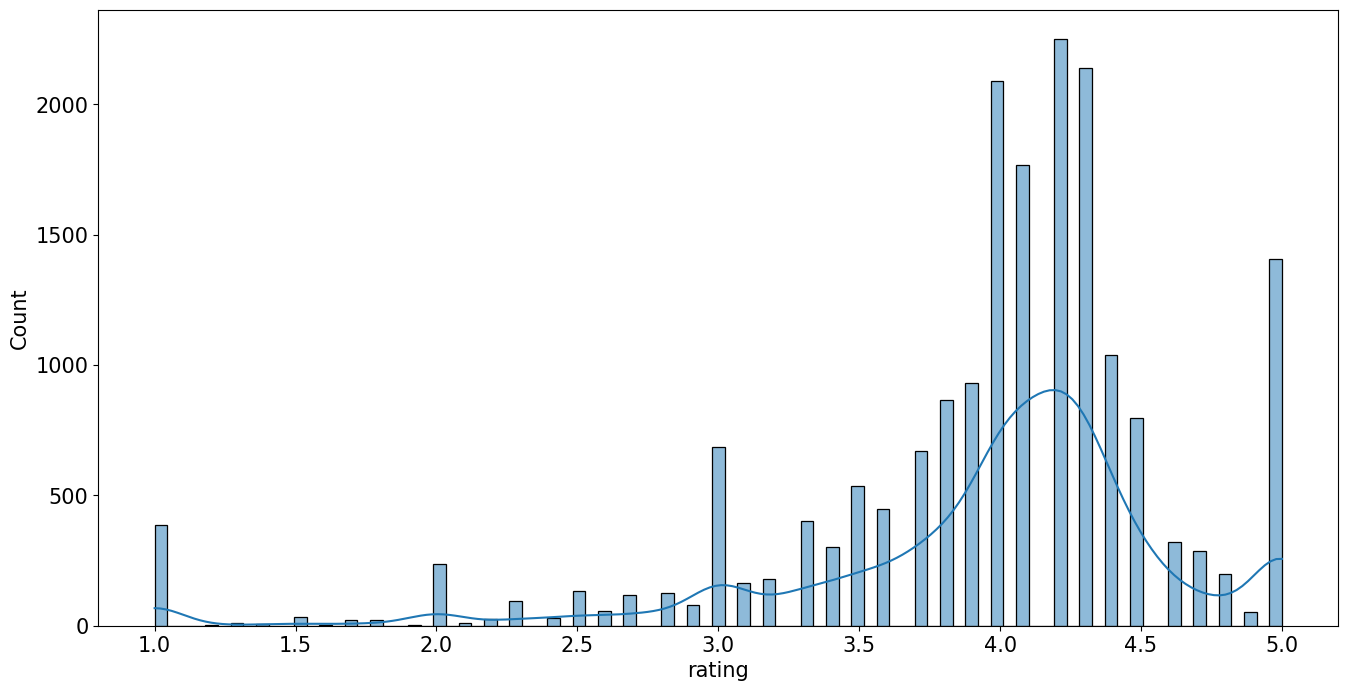

In [58]:
# Distribution of rating
sns.histplot(df.rating,kde=True)

Maximum ratings fall between 3.5 and 4.5

In [59]:
#Mean of ratings
rating_mean = df.rating.mean()
rating_mean

np.float64(3.943409583179249)

In [60]:
#Median of ratings
rating_median = df.rating.median()
rating_median

4.1

In [61]:
#filling the rating null values by mean rating
df.rating.fillna(value=rating_mean,inplace=True)

In [62]:
df['rating']

,rating
index,
1,4.1
2,2.3
3,3.4
4,3.7
5,4.4
...,...
27551,3.9
27552,4.0
27553,3.8


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27555 entries, 1 to 27555
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product       27554 non-null  object 
 1   category      27555 non-null  object 
 2   sub_category  27555 non-null  object 
 3   brand         27554 non-null  object 
 4   sale_price    27555 non-null  float64
 5   market_price  27555 non-null  float64
 6   type          27555 non-null  object 
 7   rating        27555 non-null  float64
 8   description   27440 non-null  object 
dtypes: float64(3), object(6)
memory usage: 2.1+ MB


In [64]:
df.describe()

,sale_price,market_price,rating
count,27555.000000,27555.000000,27555.00000
mean,322.514808,382.056664,3.94341
std,486.263116,581.730717,0.61255
min,2.450000,3.000000,1.00000
25%,95.000000,100.000000,3.94341
50%,190.000000,220.000000,3.94341
75%,359.000000,425.000000,4.20000
max,12500.000000,12500.000000,5.00000


# Top Selling Categories

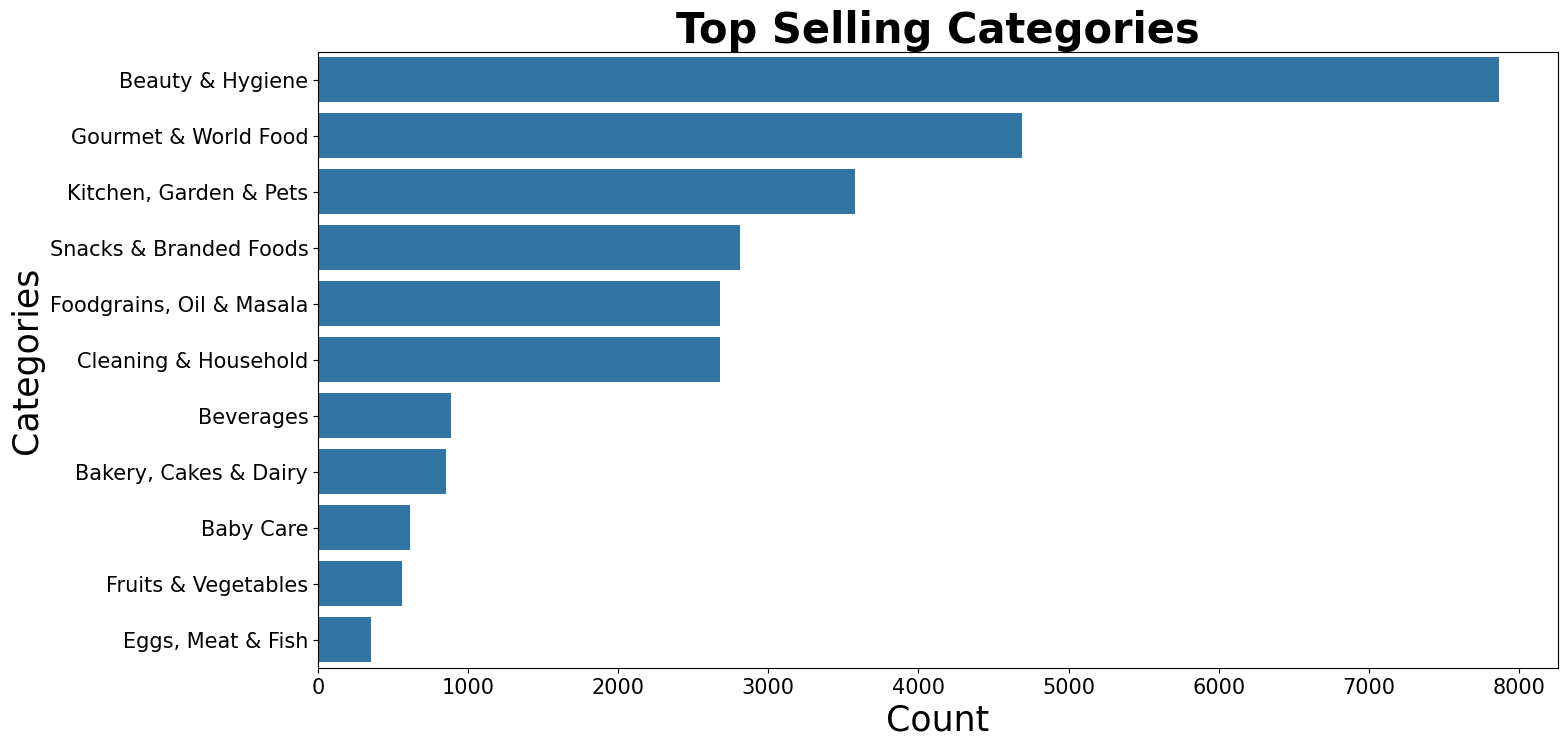

In [65]:
data = df.category.value_counts()
plt.figure(figsize=(16,8))
sns.barplot(x=data,y=data.index)
plt.xlabel('Count',fontdict={'fontsize': 25})
plt.ylabel('Categories',fontdict={'fontsize': 25})
plt.title('Top Selling Categories',fontweight="bold",fontdict={'fontsize': 30})
plt.rcParams['font.size'] = 15

# Category share to total revenue

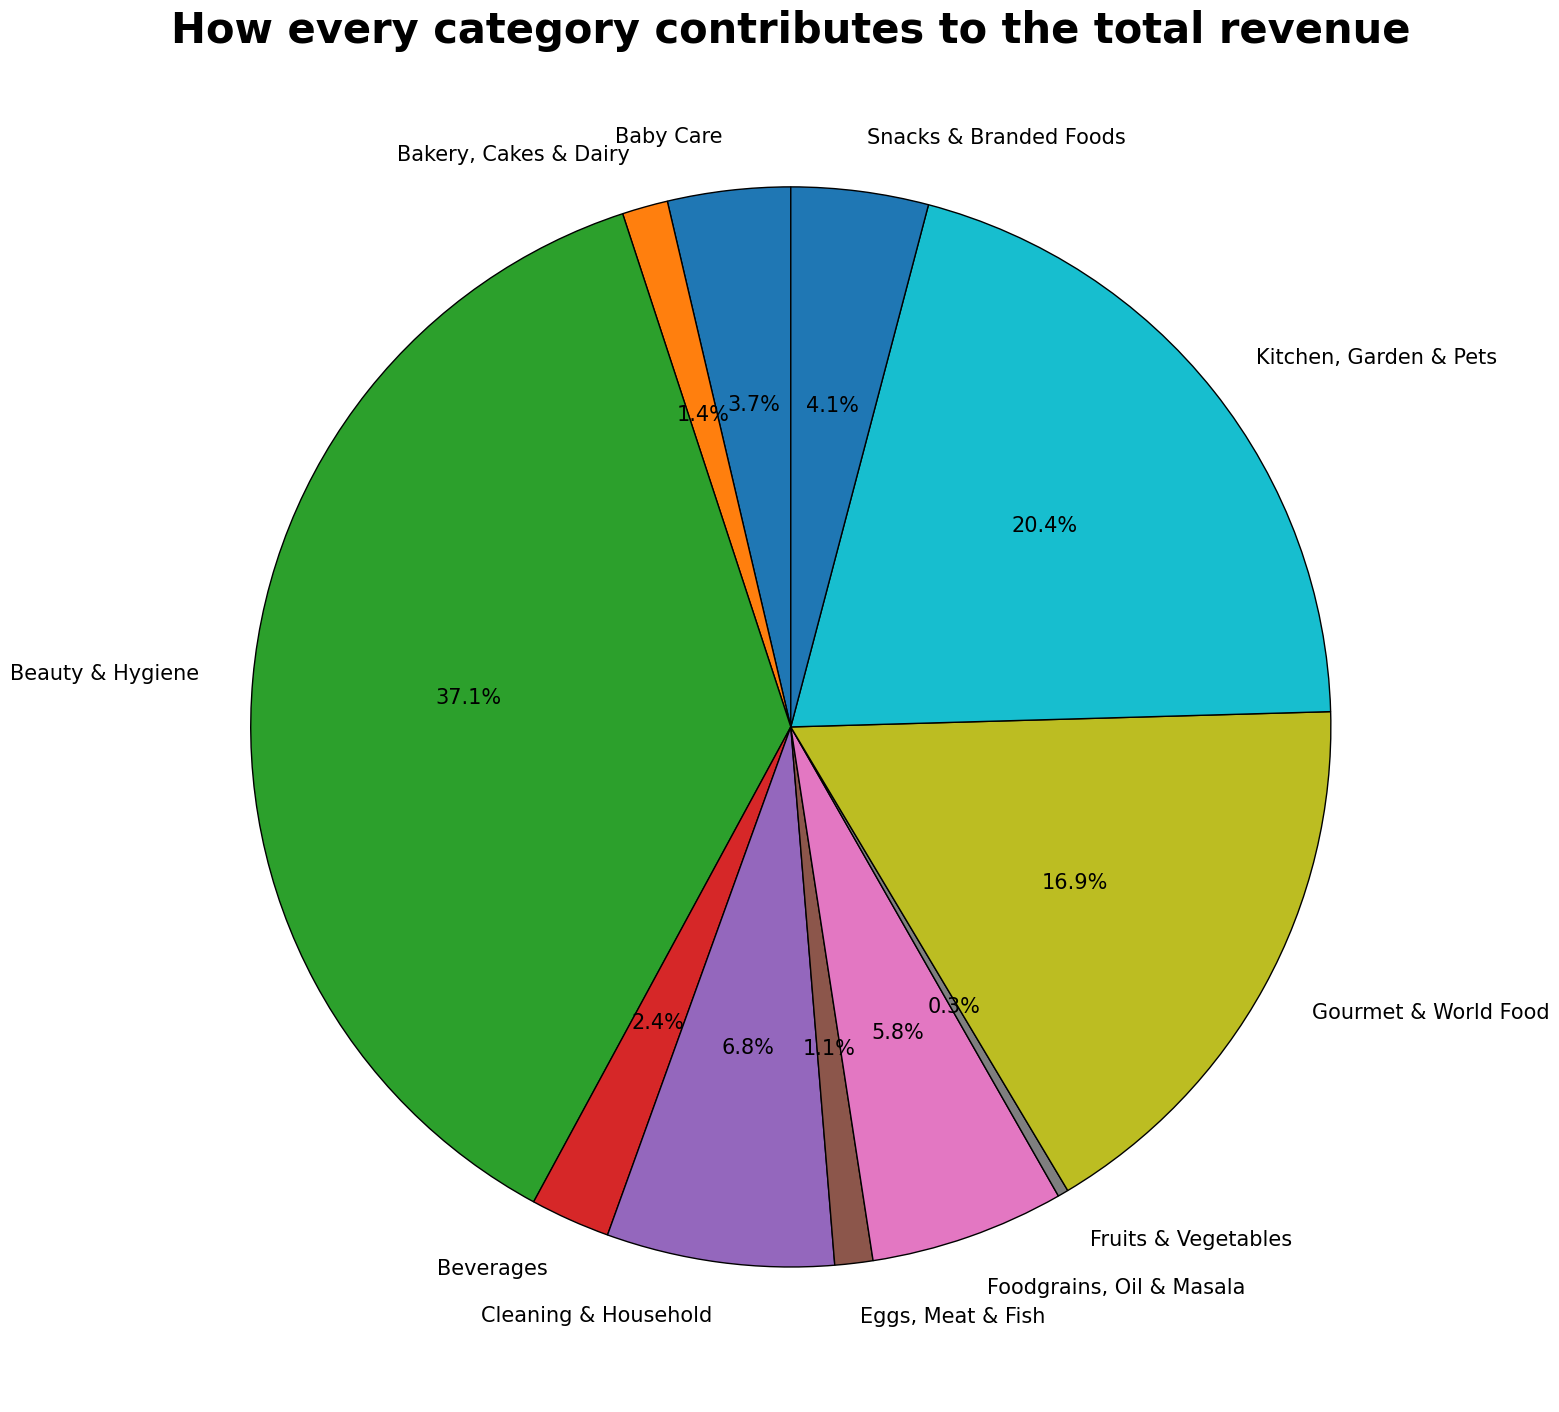

In [66]:
data = df.sale_price.groupby(df.category).sum()
plt.figure(figsize=(16,16))
plt.pie(x=data,labels=data.index,startangle=90,autopct='%1.1f%%',wedgeprops={'edgecolor':'black'})
plt.title('How every category contributes to the total revenue',fontweight="bold",fontdict={'fontsize': 30})
plt.rcParams['font.size'] = 16
plt.tight_layout()

# Top 10 Selling Products

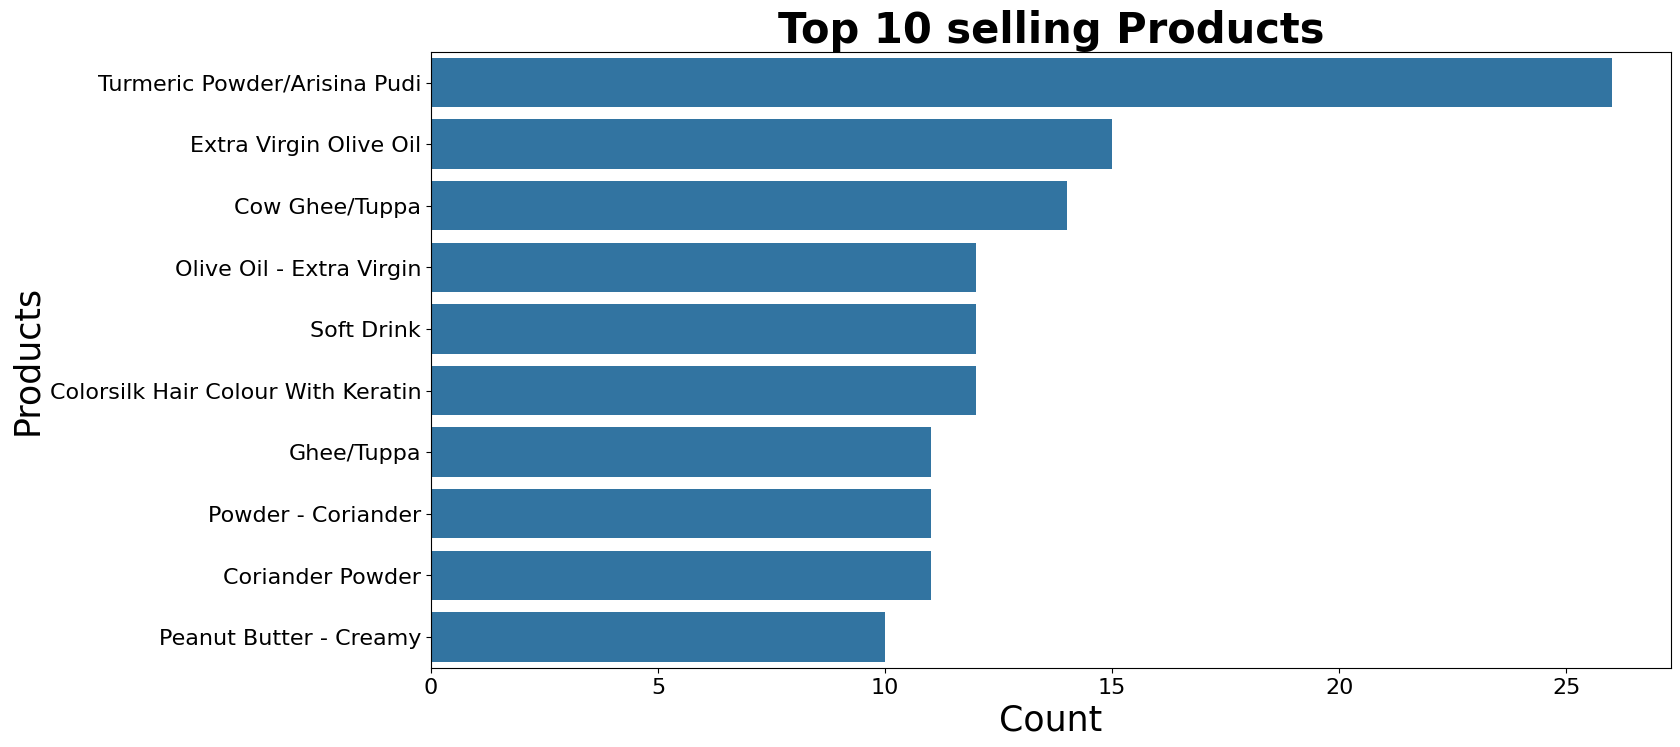

In [67]:
data = df['product'].value_counts()[:10]
plt.figure(figsize=(16,8))
sns.barplot(x=data,y=data.index)
plt.xlabel('Count',fontdict={'fontsize': 25})
plt.ylabel('Products',fontdict={'fontsize': 25})
plt.title('Top 10 selling Products',fontweight="bold",fontdict={'fontsize': 30})
plt.rcParams['font.size'] = 15


In [68]:
counts = df['brand'].value_counts()

counts_df_brand = pd.DataFrame({'Brand Name':counts.index,'Counts':counts.values})[:10]
px.bar(data_frame=counts_df_brand,
 x='Brand Name',
 y='Counts',
 color='Counts',
 color_continuous_scale='blues',
 text_auto=True,
 title=f'Top 10 Brand Items based on Item Counts')

In [69]:
df = df.drop(['description'], axis=1)

In [70]:
df

,product,category,sub_category,brand,sale_price,market_price,type,rating
index,,,,,,,,
1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.00,220.0,Hair Oil & Serum,4.1
2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.00,180.0,Water & Fridge Bottles,2.3
3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.00,250.0,Lamp & Lamp Oil,3.4
4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.00,176.0,"Laundry, Storage Baskets",3.7
5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.00,162.0,Bathing Bars & Soaps,4.4
...,...,...,...,...,...,...,...,...
27551,"Wottagirl! Perfume Spray - Heaven, Classic",Beauty & Hygiene,Fragrances & Deos,Layerr,199.20,249.0,Perfume,3.9
27552,Rosemary,Gourmet & World Food,Cooking & Baking Needs,Puramate,67.50,75.0,"Herbs, Seasonings & Rubs",4.0
27553,Peri-Peri Sweet Potato Chips,Gourmet & World Food,"Snacks, Dry Fruits, Nuts",FabBox,200.00,200.0,Nachos & Chips,3.8


# Let's create a discount column

**Discount can be created as (marketprice - saleprice)/ marketprice * 100**

In [71]:
df["discount"] = (df["market_price"] - df["sale_price"]) / df["market_price"] * 100
df.tail()

,product,category,sub_category,brand,sale_price,market_price,type,rating,discount
index,,,,,,,,,
27551,"Wottagirl! Perfume Spray - Heaven, Classic",Beauty & Hygiene,Fragrances & Deos,Layerr,199.20,249.0,Perfume,3.9,20.000000
27552,Rosemary,Gourmet & World Food,Cooking & Baking Needs,Puramate,67.50,75.0,"Herbs, Seasonings & Rubs",4.0,10.000000
27553,Peri-Peri Sweet Potato Chips,Gourmet & World Food,"Snacks, Dry Fruits, Nuts",FabBox,200.00,200.0,Nachos & Chips,3.8,0.000000
27554,Green Tea - Pure Original,Beverages,Tea,Tetley,396.00,495.0,Tea Bags,4.2,20.000000
27555,United Dreams Go Far Deodorant,Beauty & Hygiene,Men's Grooming,United Colors Of Benetton,214.53,390.0,Men's Deodorants,4.5,44.992308


In [72]:
print(f'Number of Brands is',df["brand"].nunique())
print(f'Number of Categories is',df["category"].nunique())
print(f'Number of Sub-Categories is',df["sub_category"].nunique())
print(f'Number of Products is', df["product"].nunique())
print(f'Number of Types is', df["type"].nunique())

Number of Brands is 2313
Number of Categories is 11
Number of Sub-Categories is 90
Number of Products is 23540
Number of Types is 426


In [73]:
df["product"].value_counts()

,count
product,
Turmeric Powder/Arisina Pudi,26
Extra Virgin Olive Oil,15
Cow Ghee/Tuppa,14
Olive Oil - Extra Virgin,12
Soft Drink,12
...,...
"Opalware Classique Serving Bowl - Medium, Royal Irish",1
"Lavangadi Vati - Respiratory Conditions, 300mg",1
Pomegranate - Small,1


There are a lot of unique products. Let us drop the product column

In [74]:
df = df.drop(['product', 'brand', 'type'],axis = 1)

In [75]:
df

,category,sub_category,sale_price,market_price,rating,discount
index,,,,,,
1,Beauty & Hygiene,Hair Care,220.00,220.0,4.1,0.000000
2,"Kitchen, Garden & Pets",Storage & Accessories,180.00,180.0,2.3,0.000000
3,Cleaning & Household,Pooja Needs,119.00,250.0,3.4,52.400000
4,Cleaning & Household,Bins & Bathroom Ware,149.00,176.0,3.7,15.340909
5,Beauty & Hygiene,Bath & Hand Wash,162.00,162.0,4.4,0.000000
...,...,...,...,...,...,...
27551,Beauty & Hygiene,Fragrances & Deos,199.20,249.0,3.9,20.000000
27552,Gourmet & World Food,Cooking & Baking Needs,67.50,75.0,4.0,10.000000
27553,Gourmet & World Food,"Snacks, Dry Fruits, Nuts",200.00,200.0,3.8,0.000000


In [76]:
cor = df.corr(numeric_only=True)
print(cor)

              sale_price  market_price    rating  discount
sale_price      1.000000      0.965198 -0.049231  0.016289
market_price    0.965198      1.000000 -0.062250  0.168848
rating         -0.049231     -0.062250  1.000000 -0.058877
discount        0.016289      0.168848 -0.058877  1.000000


In [77]:
df2 = df.copy()
df2 = pd.get_dummies(df2,columns=["category","sub_category"],drop_first=True)
df2

,sale_price,market_price,rating,discount,"category_Bakery, Cakes & Dairy",category_Beauty & Hygiene,category_Beverages,category_Cleaning & Household,"category_Eggs, Meat & Fish","category_Foodgrains, Oil & Masala",...,sub_category_Skin Care,sub_category_Snacks & Namkeen,"sub_category_Snacks, Dry Fruits, Nuts","sub_category_Spreads, Sauces, Ketchup",sub_category_Stationery,sub_category_Steel Utensils,sub_category_Storage & Accessories,sub_category_Tea,sub_category_Tinned & Processed Food,sub_category_Water
index,,,,,,,,,,,,,,,,,,,,,
1,220.00,220.0,4.1,0.000000,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,180.00,180.0,2.3,0.000000,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,119.00,250.0,3.4,52.400000,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,149.00,176.0,3.7,15.340909,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
5,162.00,162.0,4.4,0.000000,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27551,199.20,249.0,3.9,20.000000,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
27552,67.50,75.0,4.0,10.000000,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
27553,200.00,200.0,3.8,0.000000,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [78]:
X = df2.drop("sale_price",axis = 1)
y = df2["sale_price"]

In [79]:
X

,market_price,rating,discount,"category_Bakery, Cakes & Dairy",category_Beauty & Hygiene,category_Beverages,category_Cleaning & Household,"category_Eggs, Meat & Fish","category_Foodgrains, Oil & Masala",category_Fruits & Vegetables,...,sub_category_Skin Care,sub_category_Snacks & Namkeen,"sub_category_Snacks, Dry Fruits, Nuts","sub_category_Spreads, Sauces, Ketchup",sub_category_Stationery,sub_category_Steel Utensils,sub_category_Storage & Accessories,sub_category_Tea,sub_category_Tinned & Processed Food,sub_category_Water
index,,,,,,,,,,,,,,,,,,,,,
1,220.0,4.1,0.000000,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,180.0,2.3,0.000000,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
3,250.0,3.4,52.400000,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,176.0,3.7,15.340909,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,162.0,4.4,0.000000,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27551,249.0,3.9,20.000000,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
27552,75.0,4.0,10.000000,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
27553,200.0,3.8,0.000000,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [80]:
y

,sale_price
index,
1,220.00
2,180.00
3,119.00
4,149.00
5,162.00
...,...
27551,199.20
27552,67.50
27553,200.00


# ML Model

In [81]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RandomizedSearchCV


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **Linear Regression**

In [82]:

lr = LinearRegression()

param_dist = {
    "fit_intercept" : [True,False],
    "copy_X" : [True,False]
}

lr_reg = RandomizedSearchCV(estimator=lr,param_distributions=param_dist,
                            n_iter = 5,scoring="neg_root_mean_squared_error")

lr_reg = lr_reg.fit(X_train,y_train)


best_params = lr_reg.best_params_

lr = LinearRegression(**best_params)

In [83]:
lr.fit(X_train,y_train)
y_pred_lr = lr.predict(X_test)

mse_lr = mean_squared_error(y_test,y_pred_lr)
mae_lr = mean_absolute_error(y_test,y_pred_lr)

print(f"Mean Squared Error for Linear Regression: {mse_lr}")
print(f"Mean Absolute Error for Linear Regression: {mae_lr}")

Mean Squared Error for Linear Regression: 11329.341658254094
Mean Absolute Error for Linear Regression: 48.64274338220345


In [84]:
lr.fit(X_train,y_train)
preds = lr.predict(X_test)
mae_xgb = mean_absolute_error(y_test,preds)
rmse_xgb = np.sqrt(mean_absolute_error(y_test,preds))
score_xgb = lr.score(X_test,y_test)

In [85]:
model_performances = pd.DataFrame({
    "Model":["Linear Regression"],
    "MAE" : [str(mae_xgb)],
    "RMSE" : [str(rmse_xgb)],
    "Score" : [str(score_xgb)]
})

In [86]:
model_performances

,Model,MAE,RMSE,Score
0,Linear Regression,48.64274338220345,6.974434986592351,0.9500925620647569


# **XG BOOST**

In [87]:
#Hyperparameter Tuning
xgb = XGBRegressor(booster='gbtree', objective='reg:squarederror')

param_lst = {
    "learning_rate" : [0.1,0.01,0.3],
    "n_estimators" : [100,500,1000],
    "max_depth" : [3,6,9],
    "min_child_weight" : [1,5],
}

In [88]:
xgb_reg = RandomizedSearchCV(estimator=xgb,param_distributions=param_lst,
                            n_iter = 5,scoring="neg_root_mean_squared_error")

xgb_reg = xgb_reg.fit(X_train,y_train)

best_param = xgb_reg.best_params_

xgb = XGBRegressor(**best_param)

In [89]:
xgb.fit(X_train,y_train)
preds = xgb.predict(X_test)
mae_xgb = mean_absolute_error(y_test,preds)
rmse_xgb = np.sqrt(mean_absolute_error(y_test,preds))
score_xgb = xgb.score(X_test,y_test)

In [90]:
model_performances = pd.DataFrame({
    "Model":["XGBoost"],
    "MAE" : [str(mae_xgb)],
    "RMSE" : [str(rmse_xgb)],
    "Score" : [str(score_xgb)]
})

In [91]:
model_performances

,Model,MAE,RMSE,Score
0,XGBoost,9.455165705392721,3.0749253170431183,0.981800438612182
